<a href="https://colab.research.google.com/github/juliandavidsilvaguzman-star/Proyecto-estad-sticas-de-Youtube-Avances-IV/blob/main/Proyecto_Estadisticas_YouTube_Avances_IV_Final_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto estadísticas de YouTube | Avances IV
**Semana 10 · Cierre y evaluación del proyecto**  
**Autores:** Julián David Silva Guzmán y Jhon Eduard Tinjaca Cruz

Este notebook consolida resultados **documentados** en la ejecución de la etapa III. No simula un nuevo entrenamiento ni presenta métricas históricas como si se hubieran recalculado. Para reproducir íntegramente los modelos, ejecutar el notebook original enlazado al final.


## Propósito y alcance del proyecto

El objetivo de este documento es comparar de forma sencilla el diseño inicial de nuestro proyecto (que era una propuesta básica) frente al diseño final que efectivamente construimos (un sistema de dos etapas más robusto).

Aquí resumiremos los resultados obtenidos, los retos que enfrentamos y las soluciones que implementamos. Además, el código nos ayudará a generar tablas y gráficos para ver el rendimiento del modelo y creará un archivo descargable con todas las evidencias.

Nota: Este trabajo consolida los resultados y análisis del modelo, no representa una aplicación web interactiva ni un sistema que esté funcionando en tiempo real en internet.


In [ ]:
# Importación de librerías del sistema y del entorno
import sys
import platform

# Importación de librerías para manipulación de datos y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Imprimir información del entorno para asegurar la reproducibilidad
print("Python:", sys.version.split()[0], "| Plataforma:", platform.platform())

# Configuración de la semilla aleatoria global para consistencia en procesos estocásticos
SEED = 42
np.random.seed(SEED)

Python: 3.13.16 | Plataforma: Linux-6.6.122+-x86_64-with-glibc2.39


## Fuentes y enlaces
- Dataset: https://www.kaggle.com/datasets/advaypatil/youtube-statistics
- Colab etapa III: https://colab.research.google.com/drive/1vELCMrSn1MQv2OmY1iZcn_TmtJMsE4pF?usp=sharing
- Repositorio etapa III: https://github.com/juliandavidsilvaguzman-star/Proyecto-estad-sticas-de-Youtube-Avances-III.git



## Diseño inicial frente a diseño final

El siguiente cuadro de código crea una tabla comparativa interactiva. Su propósito es mostrar de manera muy directa cómo evolucionó la idea desde un modelo simple hasta la solución final de dos capas.

En términos sencillos, la tabla nos permite ver cinco grandes cambios:
1. **La Estructura (Arquitectura):** Pasamos de un proceso único y simple a un sistema organizado en dos partes (primero analiza el sentimiento del comentario y luego predice el desempeño del video).
2. **Procesamiento de Texto (NLP):** Mejoramos la forma en que la computadora lee los comentarios, usando un modelo de clasificación matemática (Regresión Logística).
3. **La Meta (Objetivo):** En lugar de intentar adivinar el número exacto de visitas, ahora transformamos los datos para estabilizarlos y clasificamos si un video tendrá un impacto alto o bajo.
4. **Algoritmos (Modelos):** Reemplazamos modelos básicos por técnicas avanzadas llamadas "ensambles" (que combinan lo mejor de varios modelos).
5. **Datos Utilizados (Escenarios):** Creamos dos situaciones de prueba: evaluar el rendimiento usando solo los comentarios (Escenario A) y agregar también qué tan viejo es el video (Escenario B).


In [ ]:
# Creación de un DataFrame para contrastar los cambios de diseño entre la etapa inicial y la final
comparacion = pd.DataFrame([
    ('Arquitectura', 'Pipeline único', 'Dos capas: sentimiento y desempeño'),
    ('NLP', 'TF-IDF agregado', 'TF-IDF + Regresión Logística'),
    ('Objetivo', 'Views', 'log1p(Views) y clasificación alto/bajo'),
    ('Modelos', 'Baseline y Ridge', 'Ensamblados y baselines por escenario'),
    ('Escenarios', 'Comentarios', 'A: comentarios; B: comentarios + antigüedad')
], columns=['Dimensión', 'Inicial', 'Final'])

# Desplegar la tabla comparativa de dimensiones de diseño
display(comparacion)

,Dimensión,Inicial,Final
0,Arquitectura,Pipeline único,Dos capas: sentimiento y desempeño
1,NLP,TF-IDF agregado,TF-IDF + Regresión Logística
2,Objetivo,Views,log1p(Views) y clasificación alto/bajo
3,Modelos,Baseline y Ridge,Ensamblados y baselines por escenario
4,Escenarios,Comentarios,A: comentarios; B: comentarios + antigüedad



### Métricas históricas verificadas

El siguiente bloque de código reúne y organiza en una sola tabla todas las calificaciones y resultados que obtuvieron nuestros modelos en las pruebas anteriores.

Para que la explicación sea muy sencilla, incluimos una columna llamada `origen` que indica claramente que estos datos son "históricos". Esto significa que son los resultados oficiales ya calculados y validados previamente, evitando tener que gastar tiempo y recursos ejecutando entrenamientos pesados desde cero en este momento.

La tabla te permitirá ver de un vistazo qué tan bien clasificó el modelo las emociones de la gente (sentimiento) y qué tan preciso fue prediciendo el éxito de los videos en los escenarios A y B.


In [ ]:
# Consolidación de las métricas históricas obtenidas y verificadas en la Etapa III V2
resultados = pd.DataFrame([
    ('Sentimiento', 'TF-IDF + LogReg', 'F1 macro', 0.675),
    ('Sentimiento', 'TF-IDF + LogReg', 'Accuracy', 0.759),
    ('Sentimiento (submuestra)', 'RoBERTa', 'F1 macro', 0.8526),
    ('Regresión A', 'Gradient Boosting', 'R2', 0.5448),
    ('Regresión A', 'Gradient Boosting', 'RMSE log', 1.6730),
    ('Regresión A', 'Gradient Boosting', 'MAE log', 1.2666),
    ('Clasificación A', 'XGBoost', 'F1', 0.7824),
    ('Clasificación A', 'XGBoost', 'AUC', 0.8602),
    ('Regresión B', 'XGBoost', 'R2', 0.6521),
    ('Regresión B', 'XGBoost', 'RMSE log', 1.4616),
    ('Regresión B', 'XGBoost', 'MAE log', 1.0835),
    ('Clasificación B', 'XGBoost', 'F1', 0.8242),
    ('Clasificación B', 'XGBoost', 'AUC', 0.9068),
    ('Clasificación B', 'Random Forest', 'AUC', 0.9099)
], columns=['tarea', 'modelo', 'metrica', 'valor'])

# Explicitamos que los datos provienen de ejecuciones históricas documentadas
resultados['origen'] = 'Etapa III V2 (resultado histórico)'

# Mostrar el DataFrame de resultados históricos consolidado
display(resultados)

,tarea,modelo,metrica,valor,origen
0,Sentimiento,TF-IDF + LogReg,F1 macro,0.6750,Etapa III V2 (resultado histórico)
1,Sentimiento,TF-IDF + LogReg,Accuracy,0.7590,Etapa III V2 (resultado histórico)
2,Sentimiento (submuestra),RoBERTa,F1 macro,0.8526,Etapa III V2 (resultado histórico)
3,Regresión A,Gradient Boosting,R2,0.5448,Etapa III V2 (resultado histórico)
4,Regresión A,Gradient Boosting,RMSE log,1.6730,Etapa III V2 (resultado histórico)
5,Regresión A,Gradient Boosting,MAE log,1.2666,Etapa III V2 (resultado histórico)
6,Clasificación A,XGBoost,F1,0.7824,Etapa III V2 (resultado histórico)
7,Clasificación A,XGBoost,AUC,0.8602,Etapa III V2 (resultado histórico)
8,Regresión B,XGBoost,R2,0.6521,Etapa III V2 (resultado histórico)
9,Regresión B,XGBoost,RMSE log,1.4616,Etapa III V2 (resultado histórico)



## Visualizaciones de cierre (Gráficos)

El código de abajo toma los datos de rendimiento y los convierte en un gráfico de barras muy fácil de entender.

**¿Qué estamos comparando aquí?**
Estamos evaluando la métrica $R^2$ (coeficiente de determinación) para diferentes modelos. En términos sencillos, el $R^2$ mide qué porcentaje del comportamiento de las visitas logramos predecir con nuestro modelo (mientras más cercano a 1 o 100%, mejor).

El gráfico compara visualmente:
- **Las barras azules (Escenario A):** Modelos que solo leen y analizan lo que la gente escribe en los comentarios.
- **Las barras naranjas (Escenario B):** Modelos que, además de los comentarios, toman en cuenta la antigüedad del video.

Al ver las barras, notarás de inmediato cómo las barras naranjas son notablemente más altas que las azules, demostrando de forma simple que saber qué tan viejo es un video ayuda muchísimo a predecir su éxito.


,modelo,R2_A,R2_B
0,Ridge,0.0825,0.2160
1,Random Forest,0.5313,0.6487
2,Gradient Boosting,0.5448,0.6478
3,XGBoost,0.5441,0.6521


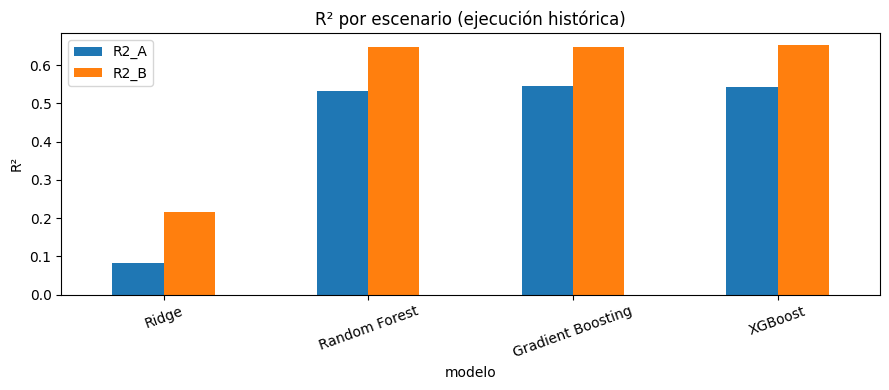

Diferencia descriptiva mejor R² B - mejor R² A: 0.1073


In [ ]:
# Definición de los coeficientes de determinación (R2) para los modelos evaluados en ambos escenarios
reg = pd.DataFrame({
    'modelo': ['Ridge', 'Random Forest', 'Gradient Boosting', 'XGBoost'],
    'R2_A': [0.0825, 0.5313, 0.5448, 0.5441],
    'R2_B': [0.2160, 0.6487, 0.6478, 0.6521]
})

# Desplegar la tabla de comparación de R2 para verificación visual
display(reg)

# Configuración de gráfico de barras para contrastar los escenarios A y B
ax = reg.set_index('modelo')[['R2_A', 'R2_B']].plot(kind='bar', figsize=(9, 4), rot=20)
ax.set_title('R² por escenario (ejecución histórica)')
ax.set_ylabel('R²')
plt.tight_layout()
plt.show() # Renderizar el gráfico

# Cálculo y visualización de la ganancia absoluta al incorporar variables temporales (Escenario B)
print('Diferencia descriptiva mejor R² B - mejor R² A:', round(0.6521 - 0.5448, 4))


## Retos encontrados y cómo los solucionamos

Durante el desarrollo del proyecto surgieron varios problemas técnicos y teóricos que podían arruinar los resultados si no se controlaban.

El bloque de código a continuación genera una tabla resumen que mapea cada problema difícil con la herramienta exacta que usamos para solucionarlo. En palabras muy sencillas, explica cómo superamos obstáculos como comentarios repetidos (duplicados), la gran diferencia entre videos con millones de visitas y otros con muy pocas (vistas asimétricas), o el alto costo de usar inteligencias artificiales muy avanzadas (Transformers).


In [ ]:
# Mapeo de retos metodológicos y las soluciones técnicas documentadas en el proyecto
retos = pd.DataFrame([
    ('Desbalance de sentimiento', 'Ponderación de clases; F1 macro'),
    ('Fuga entre comentarios de un vídeo', 'GroupKFold por Video ID y predicción OOF'),
    ('Views asimétricas', 'Transformación log1p'),
    ('Duplicados', 'Limpieza; 12 vídeos repetidos eliminados en etapa III'),
    ('Selección de modelos', 'Comparación con baselines y ensambles'),
    ('Coste de Transformers', 'RoBERTa evaluado solo en submuestra'),
    ('Interpretación', 'No confundir correlación con causalidad')
], columns=['Reto', 'Respuesta documentada'])

# Mostrar la matriz de retos y respuestas
display(retos)

,Reto,Respuesta documentada
0,Desbalance de sentimiento,Ponderación de clases; F1 macro
1,Fuga entre comentarios de un vídeo,GroupKFold por Video ID y predicción OOF
2,Views asimétricas,Transformación log1p
3,Duplicados,Limpieza; 12 vídeos repetidos eliminados en et...
4,Selección de modelos,Comparación con baselines y ensambles
5,Coste de Transformers,RoBERTa evaluado solo en submuestra
6,Interpretación,No confundir correlación con causalidad


## Lecciones aprendidas y colaboración
1. La unidad de validación debe respetar el agrupamiento por vídeo.
2. F1 macro complementa accuracy ante clases desbalanceadas.
3. Una mejora de R² no demuestra causalidad.
4. El modelo óptimo depende de la tarea, métrica y coste.
5. Reproducibilidad experimental no equivale a despliegue.

**Trabajo colaborativo:** las entregas identifican a dos autores, pero no hay evidencia suficiente para atribuir tareas individuales. Añadir commits, revisiones e incidencias al repositorio final.

## Evaluación del producto final y brechas
**Acreditado:** notebook de modelado en Colab, comparación de modelos y métricas documentadas.

**Pendiente de evidencia:** API/interfaz de inferencia, alojamiento de servicio en nube, monitorización de producción y pruebas de uso real. No marcar estas funciones como implementadas sin pruebas.


## Exportar evidencias de cierre (Descarga de archivos)

El cuadro de código final funciona como un asistente de orden. Su única tarea es empaquetar todo nuestro trabajo para que lo puedas guardar en tu computadora.

En términos muy sencillos, lo que hace este bloque es:
1. **Crear una carpeta limpia** en el sistema.
2. **Guardar las tablas** que vimos arriba en archivos de formato Excel/CSV (`.csv`), los cuales puedes abrir fácilmente con cualquier lector de hojas de cálculo.
3. **Generar un archivo de texto de procedencia** en formato JSON que explica de dónde salieron los datos originalmente.
4. **Juntar todos estos archivos en una carpeta comprimida ZIP** llamada `Evidencias_Avances_IV.zip` y descargarla automáticamente a tu computadora.

Este proceso es complementario, automático y muy seguro, ya que no modifica ninguna de tus métricas.


In [ ]:
from pathlib import Path
import json
import zipfile

# Creación del directorio local temporal para organizar las evidencias del proyecto
carpeta = Path('/content/evidencias_avances_iv')
carpeta.mkdir(parents=True, exist_ok=True)

# Exportación de cada DataFrame a formato CSV con codificación compatible (UTF-8 con BOM)
for nombre, df in [('comparacion.csv', comparacion),
                   ('resultados_historicos.csv', resultados),
                   ('retos.csv', retos),
                   ('comparacion_r2.csv', reg)]:
    df.to_csv(carpeta / nombre, index=False, encoding='utf-8-sig')

# Escritura del archivo de metadatos de procedencia en formato JSON
metadata = {
    'fuente': 'Modelo_NLP_YouTube_Colab_III_V2.ipynb - Colab.pdf',
    'tipo': 'metricas historicas, no reentrenadas',
    'semilla_referencia': 42
}
(carpeta / 'procedencia.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')

# Compresión de toda la carpeta de evidencias en un archivo ZIP para fácil descarga
zip_path = Path('/content/Evidencias_Avances_IV.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in carpeta.iterdir():
        z.write(f, arcname=f.name)

print('Evidencias listas:', zip_path)

# Intento de descarga automática interactiva dentro del entorno Google Colab
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print('Fuera de Colab: descarga manualmente el archivo generado.')

Evidencias listas: /content/Evidencias_Avances_IV.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusión y pasos a seguir

En resumen, nuestro modelo aprendió a relacionar el comportamiento de los comentarios con la popularidad de los videos.

Para entender las cifras finales de manera simple:
- En el **Escenario A** (solo comentarios), el mejor modelo explicó aproximadamente el **54.4%** de la variabilidad de las visitas ($R^2 = 0.5448$).
- En el **Escenario B** (comentarios + antigüedad del video), el rendimiento subió de forma importante, logrando explicar el **65.2%** de las visitas ($R^2 = 0.6521$).

**¿Cómo entregar este trabajo de manera correcta?**
Para finalizar tu entrega con éxito, solo debes seguir estos tres sencillos pasos:
1. Sube este archivo de notebook (`.ipynb`) a tu repositorio de GitHub.
2. Abre el notebook en Google Colab y presiona **"Entorno de ejecución" > "Ejecutar todas las celdas"** para asegurar que todos los gráficos y tablas se muestren correctamente.
3. Guarda el documento final y adjunta el enlace junto con el informe escrito en formato PDF.
